# ML model: Swiss day-ahead prices for D+2 and D+3

Implements Steps 1–5 of `ML_CONCEPT.md`. Run the cells from top to bottom; each
step can be re-run on its own after the cells above it.

| Step | Content | Status |
|---|---|---|
| 1 | Load data, local-time grid | ready |
| 2 | Fixed features, one row per (issue date D, horizon h, hour) | ready |
| 3 | Price scaler (asinh/MAD), anchor, target, price features | ready |
| 4 | Models: copy of D+1, last week, benchmark profile, Elastic Net, LightGBM | ready |
| 5 | Walk-forward evaluation and metrics | ready |
| 6 | Analysis of the errors: where, when, how extreme, what the models use | ready |

AI notice: code created with Claude (Anthropic), reviewed and adapted by the team.

In [1]:
# Libraries: lightgbm = gradient-boosted trees, sklearn = Elastic Net and scaling
import sqlite3

import itertools

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import ElasticNetCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Settings: data period, horizons, development and hold-out periods
DATABASE = "electricity_prices.db"
START = pd.Timestamp("2024-03-09")          # first day with complete weather forecasts
HORIZONS = (2, 3)                           # D+2 and D+3
DEV_START = pd.Timestamp("2025-03-10")      # first test date (after one full 365-day window)
HOLDOUT_START = pd.Timestamp("2026-05-20")  # hold-out: touched once, at the very end
WINDOW_DAYS = 365                           # training window per walk-forward step

# Chart colours and style (one colour per model, the same in every chart)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#257de0", "#f47230", "#00b894", "#f2a600", "#ee7fac"
GREY = "#666666"
plt.rcParams.update({
    "figure.figsize": (11, 3.6), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6",
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
})

## Step 1 · Data and local-time grid

Prices and weather forecasts as one row per local date and one column per hour
0–23. The 25-hour day (October) averages the two 02:00 hours, the 23-hour day
(March) interpolates the missing 02:00.

In [2]:
# Read the tables we need (vehicles and schedule define the charging hours)
with sqlite3.connect(DATABASE) as connection:
    data = pd.read_sql("SELECT * FROM ml_data", connection)
    prices_de = pd.read_sql("SELECT time_utc, price_rp_kwh FROM prices_de", connection)
    vehicles = pd.read_sql("SELECT * FROM vehicles", connection)
    schedule = pd.read_sql("SELECT * FROM schedule", connection)

# German prices only have UTC times: derive Swiss local time the same way as BuildDB_v2
prices_de["time_local"] = (pd.to_datetime(prices_de["time_utc"], utc=True)
                           .dt.tz_convert("Europe/Zurich").dt.tz_localize(None))
# Local calendar day and hour (0-23) for both tables
for frame in (data, prices_de):
    frame["time_local"] = pd.to_datetime(frame["time_local"])
    frame["date"] = frame["time_local"].dt.normalize()
    frame["hour"] = frame["time_local"].dt.hour
# Only days from START on (complete weather forecasts)
data = data[data["date"] >= START].copy()
prices_de = prices_de[prices_de["date"] >= START]


def to_grid(frame, column):
    """One row per local date, one column per hour 0-23 (DST days fixed)."""
    grid = frame.pivot_table(index="date", columns="hour", values=column, aggfunc="mean")
    return grid.interpolate(axis=1, limit=1, limit_area="inside")


# Price grids: one row per day, one column per hour
price_ch = to_grid(data, "price_rp_kwh")
price_de = to_grid(prices_de, "price_rp_kwh")

# Weather as forecast 1, 2 and 3 days ahead: weather[lead][column] is a grid
WEATHER = ["wind_de_hamburg", "wind_de_husum", "wind_de_emden", "solar_de", "solar",
           "temperature", "temperature_de"]
weather = {lead: {column: to_grid(data, f"{column}_fc_d{lead}") for column in WEATHER}
           for lead in (1, 2, 3)}

# Quick check: period covered and number of empty cells
print(f"CH prices: {len(price_ch)} days, {price_ch.index.min():%Y-%m-%d} to {price_ch.index.max():%Y-%m-%d}, "
      f"empty cells: {int(price_ch.isna().sum().sum())}")
print(f"Weather forecasts until {weather[3]['solar'].index.max():%Y-%m-%d}")

CH prices: 995 days, 2024-03-09 to 2026-11-28, empty cells: 0
Weather forecasts until 2026-11-30


## Step 2 · Fixed features

One row per issue date D, horizon h and hour k of the target day D+h. Nothing here
is fitted, so nothing can leak. Weather of the target day comes from the forecast
made h days ahead (`_fc_d2` / `_fc_d3`), weather of the known day D+1 from
`_fc_d1`. Wind and solar locations stay separate columns.

**Charging hours** (for the metrics): every hour in which any vehicle can charge,
from the earliest arrival to the latest departure in `vehicles`, plus whole days on
which some vehicle does not drive (`schedule`, 0 km).

In [3]:
def wind_cf(speed):
    """Wind speed (m/s) -> rough share of wind-turbine capacity (0-1)."""
    # Wind power grows with the cube of the wind speed, up to full capacity at ~12 m/s
    share = np.minimum(speed, 12) ** 3 / 12 ** 3
    return share.mask((speed < 3) | (speed > 25), 0)   # below cut-in or above cut-out


def weather_proxies(lead):
    """Generation and demand proxies (one grid each) from the forecast made `lead` days ahead."""
    w = weather[lead]
    return {
        # Wind in northern Germany -> share of wind-turbine capacity, per location
        "wind_cf_hamburg": wind_cf(w["wind_de_hamburg"]),
        "wind_cf_husum": wind_cf(w["wind_de_husum"]),
        "wind_cf_emden": wind_cf(w["wind_de_emden"]),
        # Radiation (W/m²) / 1000 -> rough share of solar capacity
        "solar_cf_de": (w["solar_de"] / 1000).clip(upper=1),
        "solar_cf_ch": (w["solar"] / 1000).clip(upper=1),
        # Heating degrees: how far the average CH/DE temperature is below 15 °C
        "hdd": (15 - (w["temperature"] + w["temperature_de"]) / 2).clip(lower=0),
    }


# Names of the six weather features (the keys of the dictionary above)
WEATHER_FEATURES = list(weather_proxies(1))

# Calendar per delivery day (holidays: canton of Zurich)
holiday = data.groupby("date")["holiday_ch"].max()
weekday = holiday.index.dayofweek
day_type = pd.Series(np.select([(weekday == 6) | (holiday.to_numpy() == 1), weekday == 5],
                               ["sunday_holiday", "saturday"], "workday"), index=holiday.index)

# Charging hours of the fleet
arrival = vehicles["depot_arrival"].str[:2].astype(int).min()
departure = vehicles["depot_departure"].str[:2].astype(int).max()
# Weekdays on which some vehicle does not drive (0 km) -> it can charge all day
free_weekdays = set(schedule.loc[schedule["km"] == 0, "weekday"])


def build_rows(h):
    """All rows (issue date, hour) for horizon h with the fixed features."""
    # Every combination of issue date and hour (cross join) -> 24 rows per issue date
    rows = pd.DataFrame({"issue": holiday.index}).merge(pd.DataFrame({"hour": range(24)}), how="cross")
    rows["h"] = h
    rows["anchor"] = rows["issue"] + pd.Timedelta(days=1)       # D+1, the last known day
    rows["target"] = rows["issue"] + pd.Timedelta(days=h)       # D+h, the day to predict

    # Weather proxies of the target day (forecast h days ahead) and of the known day D+1
    target_grids, anchor_grids = weather_proxies(h), weather_proxies(1)
    # (target day, hour) pairs, used to look up one value per row in the grids
    cell = pd.MultiIndex.from_arrays([rows["target"], rows["hour"]])
    # Per weather feature: value in this hour, daily mean, change vs. the known day
    for name in WEATHER_FEATURES:
        rows[name] = target_grids[name].stack().reindex(cell).to_numpy()
        target_mean = target_grids[name].mean(axis=1).reindex(rows["target"]).to_numpy()
        anchor_mean = anchor_grids[name].mean(axis=1).reindex(rows["anchor"]).to_numpy()
        rows[f"{name}_day"] = target_mean                       # level of the target day
        rows[f"d_{name}"] = target_mean - anchor_mean           # change vs. the known day

    rows["day_type"] = day_type.reindex(rows["target"]).to_numpy()
    rows["anchor_day_type"] = day_type.reindex(rows["anchor"]).to_numpy()
    # Month as a point on a circle (sin/cos), so that December and January are close together
    month = rows["target"].dt.month
    rows["month_sin"] = np.sin(2 * np.pi * month / 12)
    rows["month_cos"] = np.cos(2 * np.pi * month / 12)
    # 1 if a vehicle can charge in this hour (depot hours or a free weekday), else 0
    rows["is_charge_hour"] = ((rows["hour"] >= arrival) | (rows["hour"] < departure)
                              | rows["target"].dt.dayofweek.isin(free_weekdays)).astype(int)
    return rows


# All rows of both horizons in one table
frame = pd.concat([build_rows(h) for h in HORIZONS], ignore_index=True)
print(f"{len(frame)} rows, charging hours {arrival}:00–{departure:02d}:00 + weekdays {sorted(free_weekdays)} all day")

47856 rows, charging hours 16:00–08:00 + weekdays [6] all day


## Step 3 · Price scaler, anchor, target and price features

Fitted **inside every walk-forward step** on that step's training window only:

- z = asinh((p − m) / s) with m = median, s = 1.4826 · MAD of the CH prices
- anchor A_D = mean z of D+1; target y = z(D+h, k) − A_D
- price features: `shape_lag`, `shape_lag_week`, `de_spread`, `anchor_prev_diff`

In [4]:
class AsinhMadScaler:
    """Robust price scaling: squashes spikes and negative prices without removing them."""

    def fit(self, prices):
        # Centre (median) and spread (MAD) are hardly affected by a few extreme hours
        values = prices.stack().dropna()
        self.m = values.median()
        # 1.4826 makes the MAD comparable to a standard deviation
        self.s = 1.4826 * (values - self.m).abs().median()
        return self

    def transform(self, prices):
        # asinh: like a straight line near 0, like a log for large values, works for negative prices
        return np.arcsinh((prices - self.m) / self.s)

    def inverse(self, z):
        # Back from the scaled value z to Rp./kWh
        return self.m + self.s * np.sinh(z)


def add_price_features(rows, scaler):
    """Adds anchor, target and price features with the given (fitted) scaler."""
    # Scaled CH and DE prices; long versions with a (day, hour) index for look-ups
    z_ch, z_de = scaler.transform(price_ch), scaler.transform(price_de)
    z_long, price_long = z_ch.stack(), price_ch.stack()
    day_mean = z_ch.mean(axis=1)

    # Value of a grid at (day, hour) for every row
    def at(day, grid_long):
        return grid_long.reindex(pd.MultiIndex.from_arrays([day, rows["hour"]])).to_numpy()

    out = rows.copy()
    # Anchor A: average scaled price of the known day D+1
    out["A"] = day_mean.reindex(out["anchor"]).to_numpy()
    # Target y: scaled price of the target hour minus the anchor (= the change to predict)
    out["y"] = at(out["target"], z_long) - out["A"]
    # Price features, all relative to the anchor:
    #   shape_lag         same hour on the known day D+1
    #   shape_lag_week    same hour one week before the target day
    #   de_spread         German vs. Swiss price level on D+1
    #   anchor_prev_diff  did the level rise or fall from D to D+1?
    out["shape_lag"] = at(out["anchor"], z_long) - out["A"]
    out["shape_lag_week"] = at(out["target"] - pd.Timedelta(days=7), z_long) - out["A"]
    out["de_spread"] = z_de.mean(axis=1).reindex(out["anchor"]).to_numpy() - out["A"]
    out["anchor_prev_diff"] = out["A"] - day_mean.reindex(out["issue"]).to_numpy()
    out["price"] = at(out["target"], price_long)               # actual price, for the metrics
    out["anchor_price"] = at(out["anchor"], price_long)        # known price of D+1, same hour
    return out


PRICE_FEATURES = ["shape_lag", "shape_lag_week", "de_spread", "anchor_prev_diff"]
CATEGORICAL = ["hour", "day_type", "anchor_day_type"]
# Full feature list: calendar + weather (hour value, daily mean, change) + season + prices
FEATURES = (CATEGORICAL + WEATHER_FEATURES + [f"{n}_day" for n in WEATHER_FEATURES]
            + [f"d_{n}" for n in WEATHER_FEATURES] + ["month_sin", "month_cos"] + PRICE_FEATURES)
print(f"{len(FEATURES)} features")

27 features


## Step 4 · Models

Every model has the same interface: `fit(train)` and `predict(test)` on the rows
from Step 3, predicting y. Each must beat the ones above it.

In [5]:
class CopyD1:
    """0a: the target day looks exactly like the known day D+1, hour by hour."""
    name = "Copy of D+1"

    def fit(self, train):
        return self

    def predict(self, test):
        return test["shape_lag"].to_numpy()


class LastWeek:
    """0b: the target day looks like the same weekday one week earlier."""
    name = "Last week"

    def fit(self, train):
        return self

    def predict(self, test):
        return test["shape_lag_week"].to_numpy()


class BenchmarkProfile:
    """1: average y per (hour, day type, anchor day type); fewer than 8 rows -> average per hour."""
    name = "Benchmark profile"
    KEYS = ["hour", "day_type", "anchor_day_type"]

    def fit(self, train):
        # Average y and number of rows per (hour, day type, anchor day type)
        groups = train.groupby(self.KEYS)["y"].agg(["mean", "size"])
        # Keep only groups with at least 8 rows (otherwise the average is too noisy)
        self.profile = groups.loc[groups["size"] >= 8, "mean"]
        self.per_hour = train.groupby("hour")["y"].mean()
        return self

    def predict(self, test):
        # Look up the profile value for every test row (NaN if the group was dropped)
        cell = self.profile.reindex(pd.MultiIndex.from_frame(test[self.KEYS])).to_numpy()
        # Rows without a profile value fall back to the average per hour
        return np.where(np.isnan(cell), self.per_hour.reindex(test["hour"]).to_numpy(), cell)

### Elastic Net

Linear in the features plus hand-made interactions (hour × each wind and solar
column, hour × `hdd`, hour × day type): about 270 columns. `StandardScaler` and
the model sit in one sklearn `Pipeline`, so the scaler only ever sees training
rows. `ElasticNetCV` picks `l1_ratio` and `alpha` at every refit, with
cross-validation folds split by issue date and a 4-day gap (never row-wise).

In [6]:
HOURS = list(range(24))
DAY_TYPES = ["workday", "saturday", "sunday_holiday"]
# All non-categorical features (these go into the linear model directly)
NUMERIC = [f for f in FEATURES if f not in CATEGORICAL]


def issue_date_splits(train, n_splits=5, gap_days=4):
    """Time-ordered CV folds on issue dates: train on earlier dates, validate on later ones."""
    # All issue dates in time order
    dates = np.sort(train["issue"].unique())
    # Split the dates into 6 blocks; each of the last 5 is the validation block once
    for fold in np.array_split(dates, n_splits + 1)[1:]:
        validate = train["issue"].isin(fold)
        # Training: only dates at least gap_days before the validation block (targets must not overlap)
        fit = train["issue"] < fold[0] - np.timedelta64(gap_days, "D")
        yield np.flatnonzero(fit), np.flatnonzero(validate)


def one_hot(values, categories, prefix):
    """One-hot columns with a fixed set of categories (same columns in training and test)."""
    return pd.get_dummies(pd.Categorical(values, categories=categories), prefix=prefix, dtype=float)


def design_matrix(rows):
    """Elastic Net inputs: numeric features, one-hot calendar, hour interactions."""
    # One-hot columns for the hour and the day types
    hour = one_hot(rows["hour"], HOURS, "hour")
    day = one_hot(rows["day_type"], DAY_TYPES, "day")
    # Start with the numeric features and the one-hot calendar columns
    parts = [rows[NUMERIC].reset_index(drop=True), hour, day,
             one_hot(rows["anchor_day_type"], DAY_TYPES, "anchor_day")]
    for column in WEATHER_FEATURES:            # e.g. wind matters more at night than at noon
        parts.append(hour.mul(rows[column].to_numpy(), axis=0).add_prefix(f"{column} x "))
    for day_type_name in DAY_TYPES:            # a different daily shape per day type
        parts.append(hour.mul(day[f"day_{day_type_name}"].to_numpy(), axis=0)
                     .add_prefix(f"{day_type_name} x "))
    return pd.concat(parts, axis=1)


class ElasticNetModel:
    """2: linear model with hour interactions, regularised (L1 + L2)."""
    name = "Elastic Net"

    def fit(self, train):
        train = train.reset_index(drop=True)    # CV folds are row positions
        # Scaler + Elastic Net in one pipeline, so the scaler is fitted on training rows only.
        # ElasticNetCV tries every l1_ratio with 100 alpha values and keeps the best combination.
        self.pipeline = make_pipeline(
            StandardScaler(),
            ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 1.0], alphas=100, max_iter=10_000,
                         cv=list(issue_date_splits(train)), n_jobs=-1))
        # Train on the design matrix (features + interactions) with target y
        self.pipeline.fit(design_matrix(train), train["y"])
        return self

    def predict(self, test):
        return self.pipeline.predict(design_matrix(test))

### LightGBM

Gradient-boosted trees on the raw features, `hour` and the day types as categories,
no hand-made interactions. Monotone constraints encode the physics: more wind or
sun can only lower the price, more heating demand can only raise it. The number of
trees is chosen by early stopping on the last 60 days of each training window;
then the model is refitted on the whole window with that number of trees.

The grid (`num_leaves`, `max_depth`, `lambda_l2`) was tuned **once** on the first
year of the development period and is frozen in `LGBM_TUNED` (tuning cell below).

In [7]:
# Fixed settings: small learning rate, at least 50 rows per leaf, each tree sees
# 80 % of features and rows. n_estimators is only an upper limit (early stopping decides).
LGBM_FIXED = dict(learning_rate=0.03, min_child_samples=50, colsample_bytree=0.8, subsample=0.8,
                  subsample_freq=1, n_estimators=3000, random_state=0, verbose=-1)
# Values tried in the tuning cell below (3 x 3 x 3 = 27 combinations)
LGBM_GRID = {"num_leaves": [7, 15, 31], "max_depth": [3, 4, 6], "reg_lambda": [1, 5, 10]}
LGBM_TUNED = {2: dict(num_leaves=31, max_depth=6, reg_lambda=1),    # result of the tuning cell below
              3: dict(num_leaves=31, max_depth=6, reg_lambda=10)}

# Monotone constraints (one per feature): -1 = may only lower the prediction,
# +1 = may only raise it, 0 = free. Wind and sun lower the price, heating demand raises it.
DOWN = [c for c in WEATHER_FEATURES if c.startswith(("wind", "solar"))]
MONOTONE = [-1 if f in DOWN or f in [f"d_{c}" for c in DOWN] else
            1 if f in ("hdd", "d_hdd") else 0 for f in FEATURES]


def tree_inputs(rows):
    """LightGBM inputs: the raw features, calendar columns as categories."""
    # Categories with a fixed list, so training and test are coded the same way
    X = rows[FEATURES].copy()
    X["hour"] = pd.Categorical(X["hour"], categories=HOURS)
    for column in ("day_type", "anchor_day_type"):
        X[column] = pd.Categorical(X[column], categories=DAY_TYPES)
    return X


class LightGBMModel:
    """3: gradient-boosted trees with monotone constraints."""
    name = "LightGBM"

    def __init__(self, params=None):
        self.params = params                    # None: the frozen, tuned settings per horizon

    def fit(self, train):
        params = self.params or LGBM_TUNED[int(train["h"].iloc[0])]
        X, y = tree_inputs(train), train["y"]
        # Validation set for early stopping: the last 60 issue dates of the window
        last_60 = (train["issue"] > train["issue"].max() - pd.Timedelta(days=60)).to_numpy()
        settings = {**LGBM_FIXED, **params, "monotone_constraints": MONOTONE}
        # Probe model: stops adding trees once the error on the last 60 days has not improved for 100 trees
        probe = lgb.LGBMRegressor(**settings).fit(
            X[~last_60], y[~last_60], eval_set=[(X[last_60], y[last_60])], eval_metric="l1",
            callbacks=[lgb.early_stopping(100, verbose=False)])
        # Final model: the number of trees found above, trained on all rows
        self.model = lgb.LGBMRegressor(**{**settings, "n_estimators": probe.best_iteration_}).fit(X, y)
        return self

    def predict(self, test):
        return self.model.predict(tree_inputs(test))


# All models in the order they are compared (each should beat the ones before it)
MODELS = [CopyD1(), LastWeek(), BenchmarkProfile(), ElasticNetModel(), LightGBMModel()]

## Step 5 · Walk-forward evaluation

Monthly steps. Per step: fit the scaler and the models on the 365 days before the
step start, predict every issue date of the month. **Purge:** a training row is
only used if its target day was already known at 13:00 on the step start.

In [8]:
def walk_forward(models, start, end):
    """Predictions of all models for issue dates in [start, end), refitted monthly."""
    results = []
    # Start dates of the monthly steps
    steps = pd.date_range(start, end, freq=pd.DateOffset(months=1), inclusive="left")
    for step, step_start in enumerate(steps):
        # Test period of this step: one month (or up to `end`)
        step_end = min(step_start + pd.DateOffset(months=1), end)
        # Training window: the 365 days before the step start
        window_start = step_start - pd.Timedelta(days=WINDOW_DAYS)
        in_window = (price_ch.index >= window_start) & (price_ch.index < step_start)
        # Scaler fitted on the training window only (no information from the test month)
        scaler = AsinhMadScaler().fit(price_ch[in_window])

        # Rows of the window and the test month, with price features; drop incomplete rows
        rows = frame[(frame["issue"] >= window_start) & (frame["issue"] < step_end)]
        rows = add_price_features(rows, scaler).dropna(subset=FEATURES + ["y"])
        # Purge: a training row is only used if its target day was known at the step start
        known = rows["target"] <= step_start + pd.Timedelta(days=1)
        train = rows[(rows["issue"] < step_start) & known]
        # Test: all issue dates of this month
        test = rows[rows["issue"] >= step_start]

        for h in HORIZONS:
            train_h, test_h = train[train["h"] == h], test[test["h"] == h]
            for model in models:
                # Train on the window, predict the test month and convert back to Rp./kWh (anchor + inverse scaling)
                y_hat = model.fit(train_h).predict(test_h)
                results.append(test_h[["issue", "h", "target", "hour", "is_charge_hour", "price",
                                       "anchor_price"]].assign(
                    model=model.name, step=step,
                    price_hat=scaler.inverse(y_hat + test_h["A"].to_numpy())))
    return pd.concat(results, ignore_index=True)

### LightGBM tuning (run once, then frozen)

All 27 grid combinations, walk-forward over the first year of the development
period, scored by the MAE in the charging hours. Takes about 45 minutes, so it is
switched off; the best setting per horizon is copied into `LGBM_TUNED` above.

Result (run on 27 Nov 2026), MAE in the charging hours, Mar 2025 – Mar 2026:

| Horizon | Best: num_leaves / max_depth / lambda_l2 | MAE | Range over all 27 |
|---|---|---|---|
| D+2 | 31 / 6 / 1 | 0.795 | 0.795 – 0.826 |
| D+3 | 31 / 6 / 10 | 0.952 | 0.952 – 0.997 |

The grid matters little (about 4 % between best and worst). The best settings sit
at the upper edge of the grid (deepest trees); a larger grid might gain a little more.

In [9]:
RUN_TUNING = False

# Set to True to run the tuning again (about 45 minutes)
if RUN_TUNING:
    tuning = []
    # Try every combination of the grid values
    for values in itertools.product(*LGBM_GRID.values()):
        params = dict(zip(LGBM_GRID, values))
        tuned = walk_forward([LightGBMModel(params)], DEV_START, DEV_START + pd.DateOffset(years=1))
        # Score: MAE in the charging hours, per horizon
        for h, part in tuned[tuned["is_charge_hour"] == 1].groupby("h"):
            tuning.append({**params, "h": h, "MAE": (part["price"] - part["price_hat"]).abs().mean()})
    # Best 3 settings per horizon
    tuning = pd.DataFrame(tuning).sort_values(["h", "MAE"])
    print(tuning.groupby("h").head(3).to_string(index=False))

### Run the walk-forward (development period)

All five models, monthly refits from March 2025 to May 2026. Takes about 6 minutes.

In [10]:
# Predictions of all models for the whole development period
results = walk_forward(MODELS, DEV_START, HOLDOUT_START)
print(f"{len(results)} predictions, {results['issue'].nunique()} issue dates, "
      f"{results['step'].nunique()} monthly steps")

104640 predictions, 436 issue dates, 15 monthly steps


### Metrics

Per model and horizon. The **charging-hour** scores decide (`ML_CONCEPT.md`, Step 5).
Simplification: the "night" is taken per target day (its charging hours), not
from evening to the next morning.

- **MAE**: mean absolute error in Rp./kWh
- **Level MAE**: error of the cheapest-4-hours price of the day
- **Sign accuracy**: is the day cheaper or dearer than the known day D+1?
  (empty for rules that predict no change)
- **Spearman**: are the charging hours ranked correctly within a day?
- **Bias**: average of (prediction − actual) in the charging hours; above 0 = too high

In [11]:
def evaluate(results):
    table = []
    # One row of metrics per model and horizon
    for (model, h), part in results.groupby(["model", "h"], sort=False):
        # Only the charging hours
        charge = part[part["is_charge_hour"] == 1]
        days = charge.groupby("target")
        # Average of the 4 cheapest charging hours per day (actual, predicted, known day D+1)
        cheapest4 = lambda column: days[column].apply(lambda p: p.nsmallest(4).mean())
        level, level_hat, level_known = cheapest4("price"), cheapest4("price_hat"), cheapest4("anchor_price")
        # Sign accuracy: is it right whether the day gets cheaper or dearer than D+1?
        # Days where the model predicts no change (sign 0) are left out
        predicted_change = np.sign((level_hat - level_known).round(6))   # round: ignore float noise
        sign_ok = (predicted_change == np.sign(level - level_known))[predicted_change != 0]
        table.append({
            "model": model, "horizon": f"D+{h}",
            "MAE all hours": (part["price"] - part["price_hat"]).abs().mean(),
            "MAE charging hours": (charge["price"] - charge["price_hat"]).abs().mean(),
            "Level MAE": (level - level_hat).abs().mean(),
            "Sign accuracy": sign_ok.mean() if len(sign_ok) else np.nan,
            "Spearman": days.apply(lambda d: d["price"].corr(d["price_hat"], method="spearman")).mean(),
            "Bias": (charge["price_hat"] - charge["price"]).mean(),
        })
    return pd.DataFrame(table).set_index(["horizon", "model"]).sort_index(level=0, sort_remaining=False).round(3)


# Metrics table of the development period
scores = evaluate(results)
scores

MAE all hours  MAE charging hours  Level MAE  \
horizon model                                                             
D+2     Copy of D+1                1.520               1.179      1.215   
        Last week                  1.821               1.492      1.613   
        Benchmark profile          1.693               1.503      1.285   
        Elastic Net                1.100               0.943      0.970   
        LightGBM                   1.022               0.870      0.899   
D+3     Copy of D+1                2.097               1.648      1.846   
        Last week                  1.826               1.491      1.613   
        Benchmark profile          1.822               1.628      1.553   
        Elastic Net                1.283               1.116      1.222   
        LightGBM                   1.222               1.046      1.110   

                           Sign accuracy  Spearman   Bias  
horizon model                                              
D+2     Copy of D+1                  NaN     0.826  0.093  
        Last week                  0.654     0.866 -0.006  
        Benchmark profile          0.585     0.757 -0.042  
        Elastic Net                0.679     0.915 -0.082  
        LightGBM                   0.709     0.912 -0.071  
D+3     Copy of D+1                  NaN     0.771  0.296  
        Last week                  0.706     0.866 -0.007  
        Benchmark profile          0.665     0.758  0.019  
        Elastic Net                0.700     0.915 -0.101  
        LightGBM                   0.732     0.911 -0.035

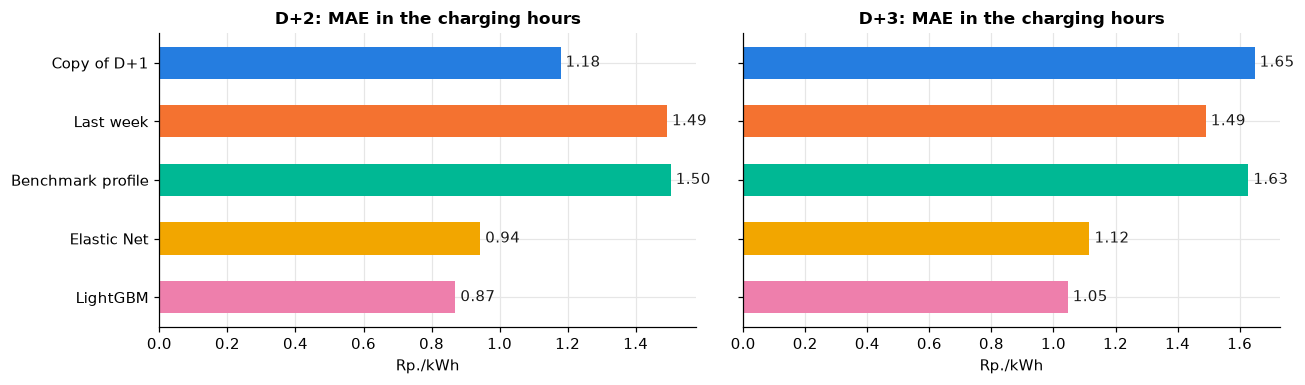

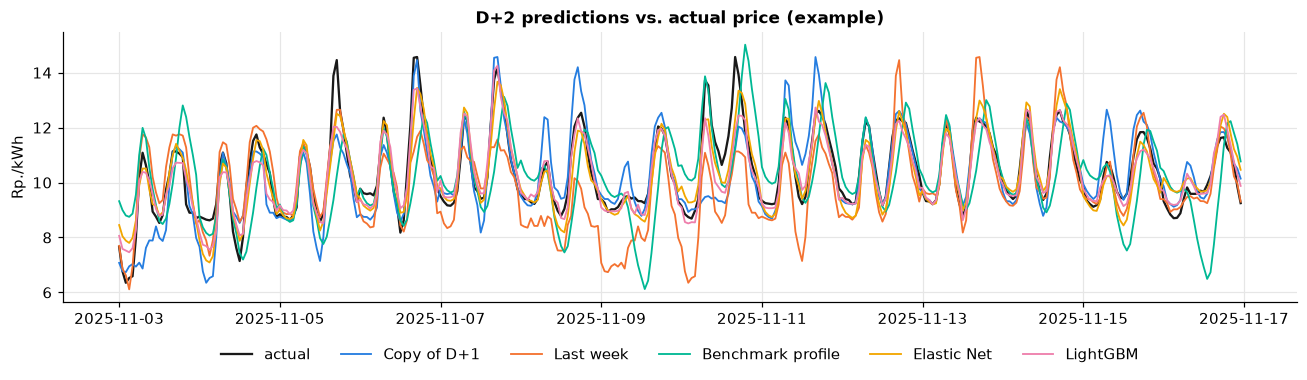

In [12]:
# One fixed colour per model
COLOURS = dict(zip([m.name for m in MODELS], [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))

# Bar chart: MAE in the charging hours per model, one panel per horizon
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, h in zip(axes, HORIZONS):
    part = scores.loc[f"D+{h}", "MAE charging hours"]
    ax.barh(part.index[::-1], part[::-1], color=[COLOURS[m] for m in part.index[::-1]], height=0.55)
    for y, value in enumerate(part[::-1]):
        ax.text(value, y, f" {value:.2f}", va="center", color="#191919")
    ax.set(title=f"D+{h}: MAE in the charging hours", xlabel="Rp./kWh")
plt.tight_layout()
plt.show()

# Example: two weeks of D+2 predictions vs. the actual price
example = results[(results["h"] == 2) & results["target"].between("2025-11-03", "2025-11-16")]
fig, ax = plt.subplots(figsize=(12, 3.6))
actual = example[example["model"] == MODELS[0].name].sort_values(["target", "hour"])
time = actual["target"] + pd.to_timedelta(actual["hour"], unit="h")
ax.plot(time, actual["price"], color="#191919", linewidth=1.5, label="actual")
# One line per model
for model, colour in COLOURS.items():
    part = example[example["model"] == model].sort_values(["target", "hour"])
    ax.plot(time, part["price_hat"].to_numpy(), color=colour, linewidth=1.2, label=model)
ax.set(title="D+2 predictions vs. actual price (example)", ylabel="Rp./kWh")
ax.legend(frameon=False, ncol=len(MODELS) + 1, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

## Step 6 · Understanding the errors

All on the development period, in Rp./kWh.

### Against the best simple rule

The bar per horizon is the better of "copy of D+1" and "last week" (charging hours).
**Improvement** = how much lower the MAE is; **days better** = share of days on which
the model's MAE is lower than the rule's (does it win consistently, or only thanks
to a few days?).

In [13]:
# Charging hours only, with the absolute error of every prediction
charge = results[results["is_charge_hour"] == 1].assign(abs_error=lambda d: (d["price_hat"] - d["price"]).abs())
# Average error per horizon, model and day (for 'days better')
daily = charge.groupby(["h", "model", "target"])["abs_error"].mean()

comparison = []
for h in HORIZONS:
    # The better of the two simple rules is the bar to beat
    rules = scores.loc[f"D+{h}"].loc[["Copy of D+1", "Last week"], "MAE charging hours"]
    best_rule = rules.idxmin()
    for model in COLOURS:
        mae = scores.loc[(f"D+{h}", model), "MAE charging hours"]
        # Improvement = how much lower the MAE is; days better = share of days the model wins
        comparison.append({
            "horizon": f"D+{h}", "model": model, "best rule": best_rule,
            "improvement": f"{1 - mae / rules.min():+.1%}",
            "days better": f"{(daily[h, model] < daily[h, best_rule]).mean():.0%}",
        })
pd.DataFrame(comparison).set_index(["horizon", "model"])

best rule improvement days better
horizon model                                                 
D+2     Copy of D+1        Copy of D+1       +0.0%          0%
        Last week          Copy of D+1      -26.5%         36%
        Benchmark profile  Copy of D+1      -27.5%         31%
        Elastic Net        Copy of D+1      +20.0%         63%
        LightGBM           Copy of D+1      +26.2%         68%
D+3     Copy of D+1          Last week      -10.5%         46%
        Last week            Last week       +0.0%          0%
        Benchmark profile    Last week       -9.2%         39%
        Elastic Net          Last week      +25.2%         70%
        LightGBM             Last week      +29.8%         77%

### Error by hour of day and by month

Where in the day does a model fail (evening peak, midday solar dip, night)? Is it
stable over the seasons? All hours, so the midday hours are visible too.

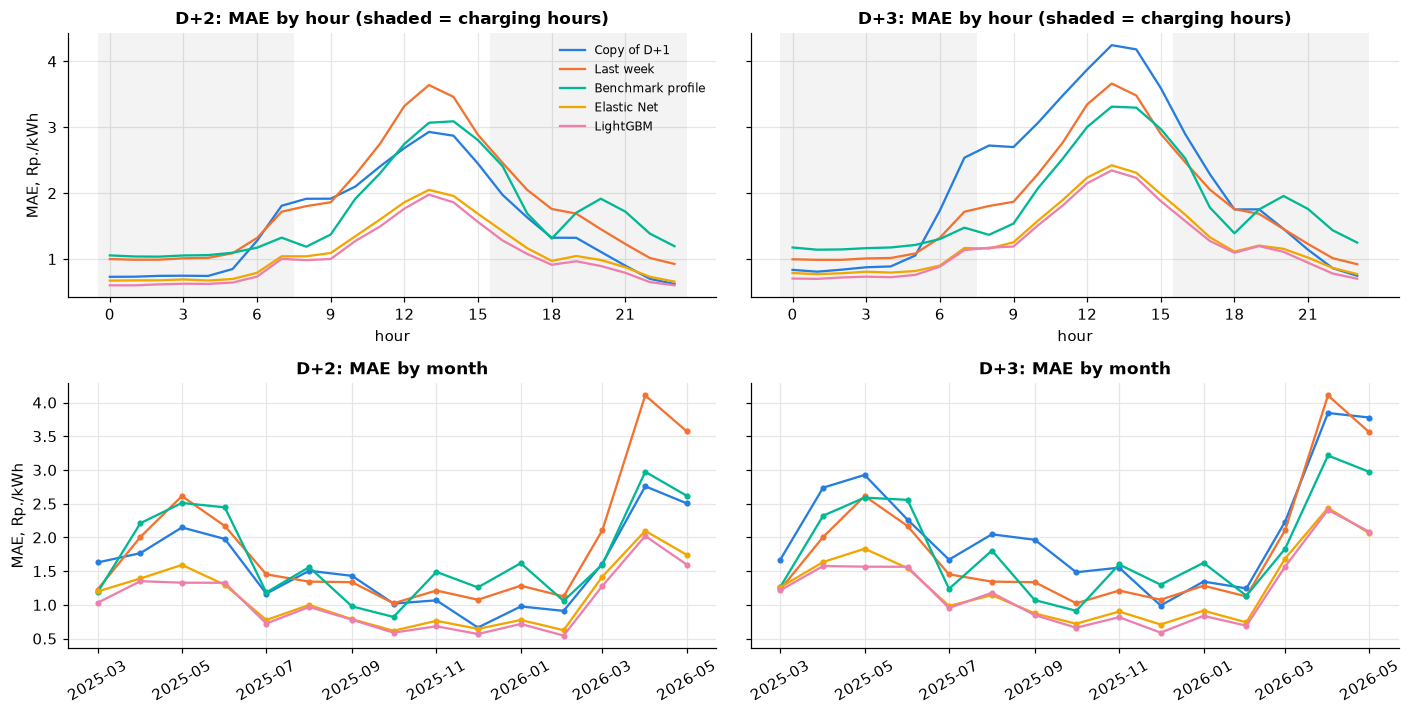

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6.6), sharey="row")
for col, h in enumerate(HORIZONS):
    # Absolute error of every prediction for this horizon
    part = results[results["h"] == h].assign(abs_error=lambda d: (d["price_hat"] - d["price"]).abs())
    # Average error per hour of day and per month, one column per model
    by_hour = part.groupby(["hour", "model"])["abs_error"].mean().unstack()
    by_month = part.groupby([part["target"].dt.to_period("M"), "model"])["abs_error"].mean().unstack()
    for model, colour in COLOURS.items():
        axes[0, col].plot(by_hour.index, by_hour[model], color=colour, label=model)
        axes[1, col].plot(by_month.index.to_timestamp(), by_month[model], color=colour,
                          marker="o", markersize=3, label=model)
    # Grey background = charging hours
    axes[0, col].axvspan(arrival - 0.5, 23.5, color=GREY, alpha=0.08, linewidth=0)
    axes[0, col].axvspan(-0.5, departure - 0.5, color=GREY, alpha=0.08, linewidth=0)
    axes[0, col].set(title=f"D+{h}: MAE by hour (shaded = charging hours)", xlabel="hour",
                     xticks=range(0, 24, 3))
    axes[1, col].set(title=f"D+{h}: MAE by month")
axes[0, 0].set_ylabel("MAE, Rp./kWh")
axes[1, 0].set_ylabel("MAE, Rp./kWh")
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[1]:
    ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()

### Extreme hours

Hours with a negative price and the 5 % most expensive hours (all hours). MAE and
bias: does a model squash the extremes towards the middle?

In [15]:
# Price threshold of the 5 % most expensive hours (each hour counted once)
expensive = results.drop_duplicates(["h", "target", "hour"])["price"].quantile(0.95)
# Three groups of hours: all, negative price, the most expensive 5 %
groups = {"all hours": results["price"].notna(), "negative price": results["price"] < 0,
          f"top 5 % (above {expensive:.1f})": results["price"] >= expensive}

extremes = {}
for label, mask in groups.items():
    # Prediction minus actual price
    error = (results["price_hat"] - results["price"])[mask]
    by_model = error.groupby([results["h"][mask].map(lambda h: f"D+{h}"), results["model"][mask]], sort=False)
    # MAE = how far off, bias = in which direction (positive = predicted too high)
    extremes[(label, "MAE")] = by_model.apply(lambda e: e.abs().mean())
    extremes[(label, "bias")] = by_model.mean()
pd.DataFrame(extremes).round(2)

all hours       negative price        \
                            MAE  bias            MAE  bias   
h   model                                                    
D+2 Copy of D+1            1.52  0.00           4.53  2.67   
    Last week              1.82  0.00           5.75  3.71   
    Benchmark profile      1.69  0.23           6.85  6.83   
    Elastic Net            1.10  0.04           4.00  3.31   
    LightGBM               1.02  0.05           3.80  2.89   
D+3 Copy of D+1            2.10  0.01           6.63  4.69   
    Last week              1.83  0.01           5.75  3.71   
    Benchmark profile      1.82  0.25           7.46  7.38   
    Elastic Net            1.28  0.01           4.84  3.98   
    LightGBM               1.22  0.10           4.85  3.93   

                      top 5 % (above 14.4)        
                                       MAE  bias  
h   model                                         
D+2 Copy of D+1                       2.25 -1.44  
    Last week                         3.03 -1.95  
    Benchmark profile                 3.01 -2.10  
    Elastic Net                       1.95 -1.50  
    LightGBM                          1.74 -1.27  
D+3 Copy of D+1                       3.01 -2.35  
    Last week                         3.03 -1.95  
    Benchmark profile                 3.23 -2.30  
    Elastic Net                       2.35 -1.94  
    LightGBM                          2.19 -1.53

### Predicted vs. actual

Best model per horizon, all hours. Points on the diagonal are perfect; a cloud
flatter than the diagonal means the model squashes extremes.

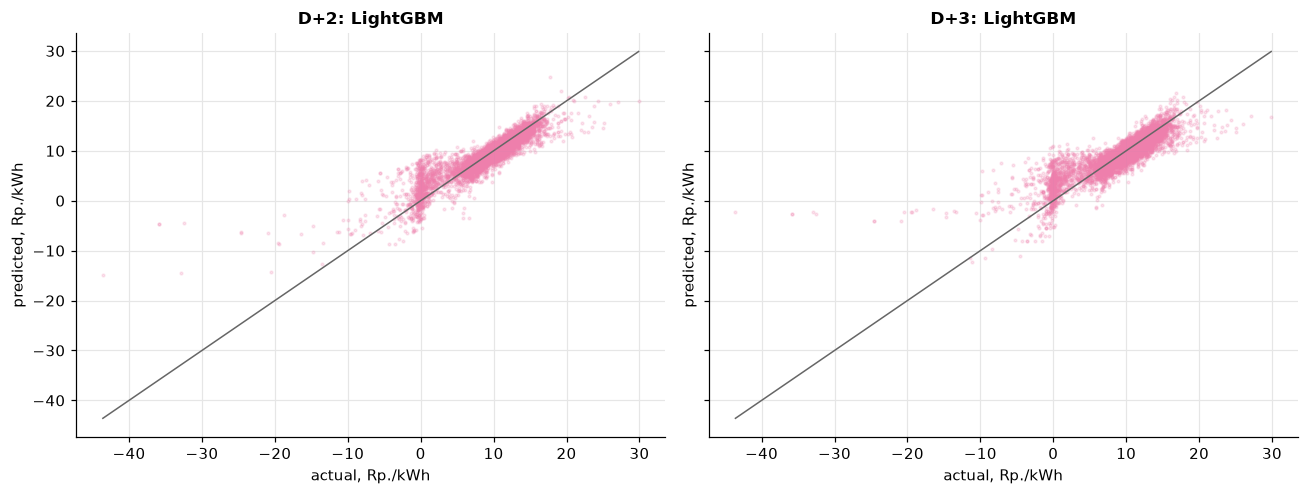

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, h in zip(axes, HORIZONS):
    # Best model of this horizon (lowest MAE in the charging hours)
    best = scores.loc[f"D+{h}", "MAE charging hours"].idxmin()
    part = results[(results["h"] == h) & (results["model"] == best)]
    ax.scatter(part["price"], part["price_hat"], s=3, alpha=0.2, color=COLOURS[best])
    low, high = part["price"].min(), part["price"].max()
    # Diagonal = perfect prediction
    ax.plot([low, high], [low, high], color=GREY, linewidth=1)
    ax.set(title=f"D+{h}: {best}", xlabel="actual, Rp./kWh", ylabel="predicted, Rp./kWh")
plt.tight_layout()
plt.show()

### What do the models use?

Both models refitted on the last training window before the hold-out.
LightGBM: share of the total gain (how much each feature improves the fit).
Elastic Net: the 12 largest coefficients on standardised inputs; the sign is the
direction of the effect on y ("x hour_k" = interaction with that hour).

D+2: Elastic Net keeps 163 of 270 columns (alpha 0.001, l1_ratio 1.0)


D+3: Elastic Net keeps 150 of 270 columns (alpha 0.002, l1_ratio 1.0)


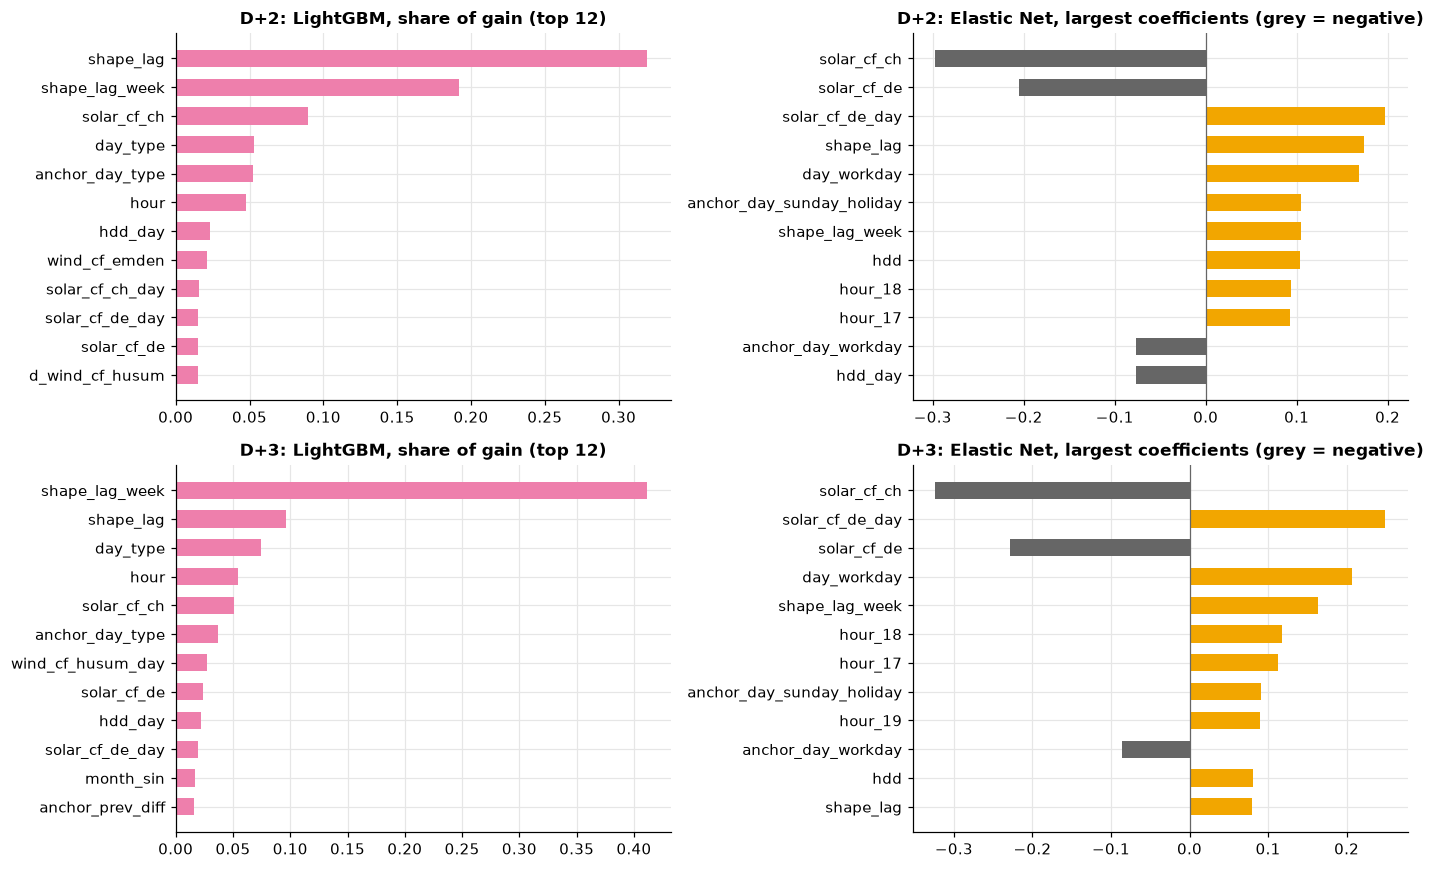

In [17]:
# Last training window before the hold-out, prepared like in the walk-forward
last_start = HOLDOUT_START - pd.Timedelta(days=WINDOW_DAYS)
scaler = AsinhMadScaler().fit(price_ch[(price_ch.index >= last_start) & (price_ch.index < HOLDOUT_START)])
last = add_price_features(frame[(frame["issue"] >= last_start) & (frame["issue"] < HOLDOUT_START)], scaler)
last = last[last["target"] <= HOLDOUT_START + pd.Timedelta(days=1)].dropna(subset=FEATURES + ["y"])

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, h in enumerate(HORIZONS):
    train_h = last[last["h"] == h]
    # LightGBM trained on this window
    trees = LightGBMModel().fit(train_h).model
    # Gain = how much a feature improved the fit in total, shown as a share of all gain
    gain = pd.Series(trees.booster_.feature_importance("gain"), index=FEATURES)
    gain = (gain / gain.sum()).nlargest(12)
    axes[row, 0].barh(gain.index[::-1], gain[::-1], color=COLOURS["LightGBM"], height=0.6)
    axes[row, 0].set(title=f"D+{h}: LightGBM, share of gain (top 12)")

    # Elastic Net on the same window; columns with coefficient 0 were dropped by the L1 penalty
    linear = ElasticNetModel().fit(train_h).pipeline
    coef = pd.Series(linear[-1].coef_, index=design_matrix(train_h.head(1)).columns)
    # The 12 largest coefficients by absolute value
    top = coef[coef.abs().nlargest(12).index][::-1]
    axes[row, 1].barh(top.index, top, height=0.6,
                      color=[COLOURS["Elastic Net"] if c > 0 else GREY for c in top])
    axes[row, 1].axvline(0, color=GREY, linewidth=0.8)
    axes[row, 1].set(title=f"D+{h}: Elastic Net, largest coefficients (grey = negative)")
    print(f"D+{h}: Elastic Net keeps {(coef != 0).sum()} of {len(coef)} columns "
          f"(alpha {linear[-1].alpha_:.3f}, l1_ratio {linear[-1].l1_ratio_})")
plt.tight_layout()
plt.show()

### Findings (development period, Mar 2025 – May 2026)

- **Both real models clearly beat the simple rules; LightGBM is best for both horizons.** MAE in the charging hours: 0.87 Rp./kWh for D+2 (26 % better than copying D+1) and 1.05 for D+3 (30 % better than last week). It wins on 68 % (D+2) and 77 % (D+3) of the days, so the gain is consistent, not driven by a few days. The Elastic Net is close behind (0.94 / 1.12).
- **Decision quality improves less than the MAE.** "Cheaper or dearer than the known day" is right on 71 % / 73 % of days (last week: 65 % / 71 %); the ranking of the hours improves from 0.87 to 0.91 (Spearman).
- **Where:** midday (11–15 h, solar) has the largest errors for every model; in the charging hours the error is about 0.6–1.2 Rp./kWh. **When:** spring (April–May) is hardest (solar surplus, negative prices); the real models roughly halve the rules' errors there.
- **Extremes are squashed:** negative-price hours are predicted about 3–4 Rp./kWh too high, the top 5 % about 1.3–1.5 too low. Overall the bias is close to zero.
- **What the models use:** LightGBM relies mostly on the known shapes (`shape_lag` for D+2, `shape_lag_week` for D+3), then solar and the calendar; wind ranks lower. The Elastic Net ends up as a pure Lasso (l1_ratio 1.0) keeping about 150–160 of 270 columns; sun lowers the price, workdays and evening hours raise it.
- **A few days are far off:** the worst days are sunny Sundays and holidays in spring (e.g. Easter Sunday and Monday 2026, 11 May 2025, 26 Apr 2026), with prices deep below zero; LightGBM predicts them 3–6 Rp./kWh too expensive. Sudden level jumps (4–5 Mar 2026) are predicted too low. The worst 10 % of days cause about 27 % of the total error. **Potential improvement:** German holidays (`holiday_de`) as a feature and an interaction solar × Sunday/holiday; matters because Sundays are whole-day charging days.
- **Tuning matters little:** about 4 % between the best and worst LightGBM setting.

## Step 7 · Hold-out (run once)

All choices (features, models, LightGBM settings) were made on the development
period. The hold-out, 20 May 2026 to the latest day with known prices, was
**not** looked at before and is run exactly once. Its numbers are the honest
final result; nothing is changed afterwards because of them.

It includes the steep price rise since September 2026, a level the models never
saw in training.

In [18]:
# Hold-out: from HOLDOUT_START up to the latest day with known prices, evaluated once
HOLDOUT_END = price_ch.index.max() + pd.Timedelta(days=1)   # up to the latest known day
holdout = walk_forward(MODELS, HOLDOUT_START, HOLDOUT_END)
holdout_scores = evaluate(holdout)
print(f"{len(holdout)} predictions, issue dates {holdout['issue'].min():%Y-%m-%d} to "
      f"{holdout['issue'].max():%Y-%m-%d}, {holdout['step'].nunique()} monthly steps")
holdout_scores

45720 predictions, issue dates 2026-05-20 to 2026-11-26, 7 monthly steps


MAE all hours  MAE charging hours  Level MAE  \
horizon model                                                             
D+2     Copy of D+1                2.185               1.619      1.469   
        Last week                  2.608               2.284      1.931   
        Benchmark profile          3.042               2.865      2.231   
        Elastic Net                1.827               1.628      1.413   
        LightGBM                   1.656               1.479      1.319   
D+3     Copy of D+1                3.055               2.379      2.381   
        Last week                  2.605               2.291      1.934   
        Benchmark profile          3.280               3.180      2.669   
        Elastic Net                2.122               1.965      1.748   
        LightGBM                   1.959               1.789      1.643   

                           Sign accuracy  Spearman   Bias  
horizon model                                              
D+2     Copy of D+1                  NaN     0.841  0.021  
        Last week                  0.602     0.876 -0.414  
        Benchmark profile          0.565     0.753  0.117  
        Elastic Net                0.649     0.920 -0.015  
        LightGBM                   0.675     0.918  0.139  
D+3     Copy of D+1                  NaN     0.790  0.292  
        Last week                  0.689     0.876 -0.416  
        Benchmark profile          0.600     0.753  0.207  
        Elastic Net                0.658     0.923  0.015  
        LightGBM                   0.705     0.916  0.223

### Development vs. hold-out

MAE in the charging hours, improvement over the better simple rule and share of
days better than that rule, side by side.

In [19]:
def against_rules(scores, results):
    """Charging-hour MAE, improvement over the best simple rule, share of days better."""
    # Charging hours only
    charge = results[results["is_charge_hour"] == 1]
    # Average error per horizon, model and day (for 'days better')
    daily = (charge["price_hat"] - charge["price"]).abs().groupby(
        [charge["h"], charge["model"], charge["target"]]).mean()
    table = []
    for h in HORIZONS:
        # The better of the two simple rules is the bar to beat
        rules = scores.loc[f"D+{h}"].loc[["Copy of D+1", "Last week"], "MAE charging hours"]
        for model in COLOURS:
            mae = scores.loc[(f"D+{h}", model), "MAE charging hours"]
            table.append({"horizon": f"D+{h}", "model": model, "MAE": round(mae, 2),
                          "improvement": f"{1 - mae / rules.min():+.0%}",
                          "days better": f"{(daily[h, model] < daily[h, rules.idxmin()]).mean():.0%}"})
    return pd.DataFrame(table).set_index(["horizon", "model"])


# Development and hold-out side by side
pd.concat({"development": against_rules(scores, results),
           "hold-out": against_rules(holdout_scores, holdout)}, axis=1)

development                         hold-out  \
                                  MAE improvement days better      MAE   
horizon model                                                            
D+2     Copy of D+1              1.18         +0%          0%     1.62   
        Last week                1.49        -27%         36%     2.28   
        Benchmark profile        1.50        -27%         31%     2.86   
        Elastic Net              0.94        +20%         63%     1.63   
        LightGBM                 0.87        +26%         68%     1.48   
D+3     Copy of D+1              1.65        -11%         46%     2.38   
        Last week                1.49         +0%          0%     2.29   
        Benchmark profile        1.63         -9%         39%     3.18   
        Elastic Net              1.12        +25%         70%     1.96   
        LightGBM                 1.05        +30%         77%     1.79   

                                                   
                          improvement days better  
horizon model                                      
D+2     Copy of D+1               +0%          0%  
        Last week                -41%         32%  
        Benchmark profile        -77%         19%  
        Elastic Net               -1%         54%  
        LightGBM                  +9%         61%  
D+3     Copy of D+1               -4%         50%  
        Last week                 +0%          0%  
        Benchmark profile        -39%         34%  
        Elastic Net              +14%         62%  
        LightGBM                 +22%         65%

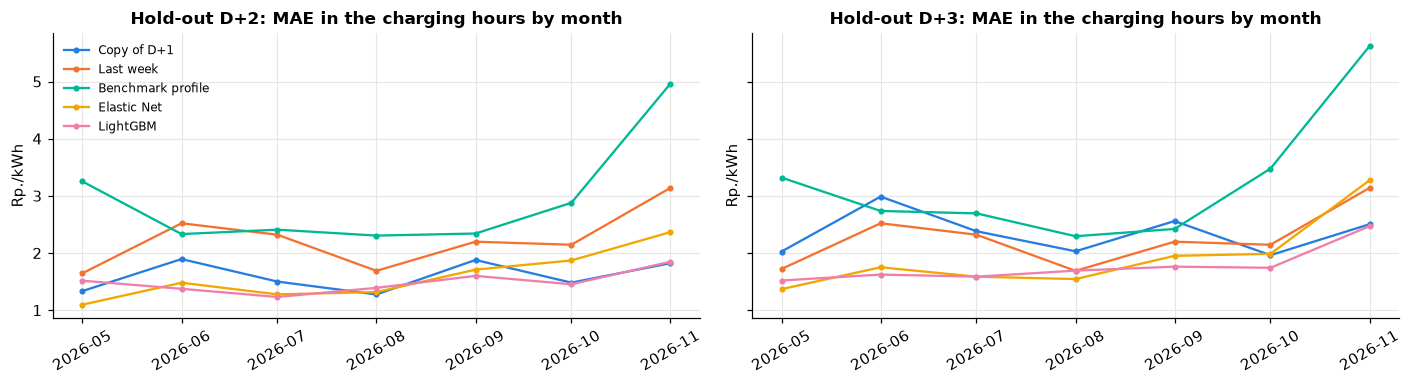

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, h in zip(axes, HORIZONS):
    # Hold-out predictions of this horizon, charging hours only
    part = holdout[(holdout["h"] == h) & (holdout["is_charge_hour"] == 1)]
    # MAE per month and model
    by_month = (part["price_hat"] - part["price"]).abs().groupby(
        [part["target"].dt.to_period("M"), part["model"]]).mean().unstack()
    for model, colour in COLOURS.items():
        ax.plot(by_month.index.to_timestamp(), by_month[model], color=colour, marker="o",
                markersize=3, label=model)
    ax.set(title=f"Hold-out D+{h}: MAE in the charging hours by month", ylabel="Rp./kWh")
    ax.tick_params(axis="x", labelrotation=30)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

### Hold-out findings (20 May – 28 Nov 2026)

- **LightGBM stays the best model for both horizons**: MAE in the charging hours 1.48 Rp./kWh for D+2 and 1.79 for D+3; better than the best simple rule on 61 % and 65 % of the days.
- **The lead over the simple rules shrinks**, above all for D+2: +9 % over copying D+1 (development: +26 %). For D+3 it holds up better: +22 % over last week (development: +30 %). The Elastic Net no longer beats copying D+1 for D+2 (−1 %), but still beats last week for D+3 (+14 %).
- **All errors are larger in absolute terms because prices are higher and more volatile**: average price in the charging hours 16.1 vs. 9.9 Rp./kWh, standard deviation 6.4 vs. 3.5. *Relative* to the price level, LightGBM's error is almost unchanged: about 9 % (D+2) and 11 % (D+3) in both periods. Predicting the change vs. the known day carried over to the new price level as intended.
- **The benchmark profile breaks down** (−77 % for D+2): its fixed average daily shapes, learned at the old price level, no longer fit. The copy rule adapts automatically because it uses yesterday's real prices.
- **Errors rise in November 2026** for every model, at the highest prices of the whole data set.
- **Ranking of the hours stays good** (Spearman 0.92, same as development); "cheaper or dearer than the known day" is right on 68 % / 71 % of days (development: 71 % / 73 %).

**Why the lead shrinks although the walk-forward refits every month:**

| Error relative to the price level | Development | Hold-out |
|---|---|---|
| D+2 copy of D+1 | 11.9 % | 10.0 % (rule got *better*) |
| D+2 LightGBM | 8.8 % | 9.2 % (slightly worse) |
| D+3 last week | 15.1 % | 14.2 % (rule got better) |
| D+3 LightGBM | 10.6 % | 11.1 % (slightly worse) |

- *The simple rule got better:* prices rose by 62 %, but the day-to-day changes only by 37 %. Autumn 2026 was driven by a high, persistent price level (fuel, demand) rather than by weather swings, which is exactly when copying the known day is hard to beat. The model's advantage comes from weather information, which explained less of the price movement in this period.
- *The model adapts with a delay:* every refit uses the last 365 days. In November 2026 only about 2 of the 12 months in the training window were at the new price level, so the learned weather and calendar corrections were still calibrated to the old level, and the price scaler was fitted on the old prices.

**Potential improvements** (not tested: the hold-out has now been seen, so any change made because of it could not be evaluated honestly on it; testing needs new data):
- a shorter training window (e.g. 180 days) or higher weights for recent data
- weekly instead of monthly refits
- the price level itself (anchor A_D) as a feature, so the model knows which price regime it is in

**Conclusion:** the model generalises to a period it never saw, including a doubled price level, but its advantage over simply copying the known day is smaller there (D+2: +9 %). For D+3, where no day can be copied, it remains clearly useful (+22 %).

## Next steps

1. `ml_model.py`: train the final LightGBM on the latest 365 days and write the daily D+2 / D+3 predictions to the `predictions` table for the app.
2. Charging plan per vehicle and policy backtest (`ML_CONCEPT.md`, Steps 6–7).